# Average baseline scores: full and tiny datasets

Compare each method's average **test score** across **full (whole)** datasets and **tiny** datasets, using the JSON reports in `baselines/results/`.

Each dataset has equal weight within its group; node counts do not affect the average. Tiny subsamples (`-t-N`) count as separate datasets. If multiple seeds are available, their scores are averaged per dataset first. Duplicate copies of a run count only once.

Scores stay in their original units: average precision (AP), accuracy, and R². The combined mean is a descriptive average of different metrics, not an accuracy percentage; negative R² scores are retained. The current results contain 10 full and 50 tiny datasets per method.


From the repository root, install the plotting environment and open this notebook:

```bash
python3 -m pip install -r baselines/requirements-notebook.txt
python3 -m jupyterlab baselines/plot_results.ipynb
```

Run all cells in order. Change `SCORE_SPLIT` below to `"val"` for validation scores, or edit `RESULT_FILES` to select specific reports.


In [5]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SCORE_SPLIT = "test"  # "test" or "val"
DATA_SPLIT = "RL"

# Works when launched from the repository root, baselines/, or results/.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "baselines" / "results").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Open the notebook from this repository.")

RESULT_FILES = sorted((REPO_ROOT / "baselines" / "results").glob("*.json"))
if not RESULT_FILES:
    raise FileNotFoundError("No JSON reports found in baselines/results.")
if SCORE_SPLIT not in {"test", "val"}:
    raise ValueError('SCORE_SPLIT must be "test" or "val".')

METHOD_LABELS = {
    "rf50": "RF-50",
    "rf500": "RF-500",
    "rf50_nfa": "RF-50 + NFA",
    "rf500_nfa": "RF-500 + NFA",
}
VARIANTS = ["full", "tiny"]


In [6]:
rows = []
for path in RESULT_FILES:
    report = json.loads(path.read_text())
    for record in report["results"]:
        rows.append({
            "source": path.name,
            "dataset": record["dataset"],
            "base_dataset": record["base_dataset"],
            "variant": record["variant"],
            "model": record["model"],
            "seed": record["seed"],
            "split": record["split"],
            "metric": record.get("metric"),
            "status": record["status"],
            "score": record.get("scores", {}).get(SCORE_SPLIT),
        })

runs = pd.DataFrame(rows)
if runs.empty:
    raise ValueError("The selected reports contain no results.")
runs = runs.loc[runs["split"].eq(DATA_SPLIT)].copy()
if runs.empty:
    raise ValueError(f"No results for data split {DATA_SPLIT!r}.")
if not runs["variant"].isin(VARIANTS).all():
    raise ValueError("Expected dataset variants 'full' and 'tiny'.")

runs["score"] = pd.to_numeric(runs["score"], errors="raise")
valid = runs["status"].eq("ok") & np.isfinite(runs["score"])
if not valid.all():
    display(runs.loc[~valid, ["source", "dataset", "model", "status", "score"]])
    raise ValueError(
        "Some selected runs failed or lack a finite score. "
        "Select complete reports in RESULT_FILES before comparing averages."
    )

# Avoid weighting repeated checkpoint copies as additional seeds.
run_key = ["dataset", "variant", "model", "seed", "split"]
runs = runs.drop_duplicates(subset=run_key + ["base_dataset", "metric", "score"])
if runs.duplicated(run_key).any():
    raise ValueError(
        "Conflicting scores for the same dataset, method, seed, and split. "
        "Select one report for each run in RESULT_FILES."
    )

print(f"Reports: {', '.join(path.name for path in RESULT_FILES)}")
print(f"Evaluation: {SCORE_SPLIT} scores | data split: {DATA_SPLIT}")
print(f"Unique runs: {len(runs)} | seeds: {sorted(runs['seed'].unique())}")


Reports: graphland_rf.json
Evaluation: test scores | data split: RL
Unique runs: 240 | seeds: [np.int64(42)]


In [7]:
# First average seeds, then average datasets with equal weight.
dataset_scores = (
    runs.groupby(["base_dataset", "model", "variant", "dataset"], as_index=False)
    .agg(score=("score", "mean"), seeds=("seed", "nunique"))
)
method_order = [model for model in METHOD_LABELS if model in runs["model"].unique()]
method_order += sorted(set(runs["model"]) - set(method_order))

# Each method must cover the same datasets for a comparable bar chart.
coverage = {
    model: set(zip(group["variant"], group["dataset"]))
    for model, group in dataset_scores.groupby("model")
}
if any(datasets != coverage[method_order[0]] for datasets in coverage.values()):
    raise ValueError("Methods cover different datasets; select matching reports.")

summary = (
    dataset_scores.groupby(["model", "variant"])
    .agg(mean_score=("score", "mean"), datasets=("dataset", "nunique"))
)
mean_scores = summary["mean_score"].unstack("variant").reindex(
    index=method_order, columns=VARIANTS
)
dataset_counts = summary["datasets"].unstack("variant").reindex(
    index=method_order, columns=VARIANTS
)
if mean_scores.isna().any().any():
    raise ValueError("Each method needs results for both full and tiny datasets.")

summary_table = pd.DataFrame({
    "Full mean": mean_scores["full"],
    "Full datasets": dataset_counts["full"],
    "Tiny mean": mean_scores["tiny"],
    "Tiny datasets": dataset_counts["tiny"],
}).rename(index=METHOD_LABELS)
summary_table.index.name = "Method"
display(summary_table.round(4))


,Full mean,Full datasets,Tiny mean,Tiny datasets
Method,,,,
RF-50,0.4076,10,0.1597,50
RF-500,0.4221,10,0.1673,50
RF-50 + NFA,0.5111,10,0.2046,50
RF-500 + NFA,0.5288,10,0.2156,50


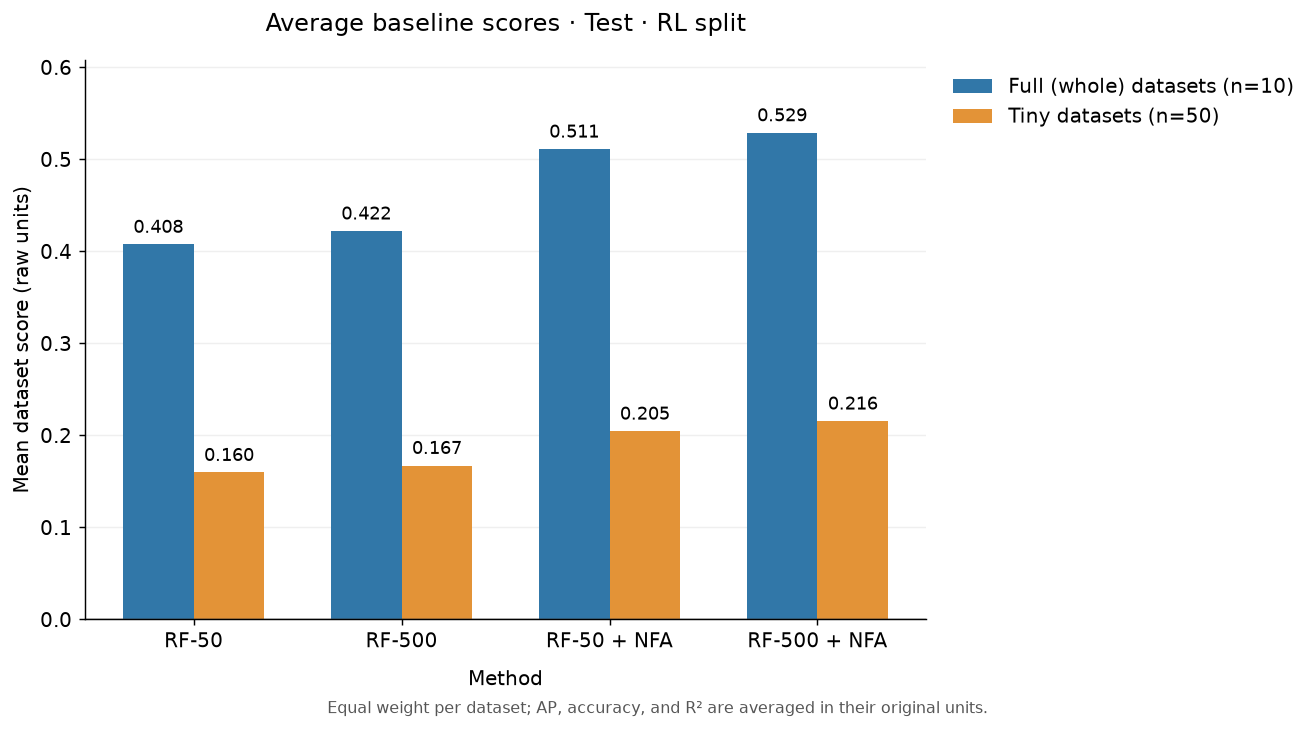

In [8]:
plt.rcParams.update({
    "figure.dpi": 130,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
x = np.arange(len(method_order))
width = 0.34
colors = {"full": "#3177A8", "tiny": "#E39337"}
group_labels = {"full": "Full (whole) datasets", "tiny": "Tiny datasets"}

for offset, variant in zip((-width / 2, width / 2), VARIANTS):
    n_datasets = int(dataset_counts[variant].iloc[0])
    bars = ax.bar(
        x + offset,
        mean_scores[variant],
        width,
        color=colors[variant],
        label=f"{group_labels[variant]} (n={n_datasets})",
    )
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)

split_label = {"test": "Test", "val": "Validation"}[SCORE_SPLIT]
ax.set_title(f"Average baseline scores · {split_label} · {DATA_SPLIT} split", pad=16)
ax.set_ylabel("Mean dataset score (raw units)")
ax.set_xticks(x, [METHOD_LABELS.get(model, model) for model in method_order])
ax.set_xlabel("Method", labelpad=10)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.axhline(0, color="#666666", linewidth=0.8)

# Include zero and retain negative averages without clipping their labels.
values = mean_scores.to_numpy()
low = min(0.0, float(values.min()))
high = max(0.0, float(values.max()))
padding = max(high - low, 0.1) * 0.15
ax.set_ylim(low - padding if low < 0 else 0, high + padding)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))

fig.supxlabel(
    "Equal weight per dataset; AP, accuracy, and R² are averaged in their original units.",
    fontsize=9,
    color="#555555",
)
plt.show()

# Optional export:
# fig.savefig(REPO_ROOT / "baselines" / "average_scores.png", dpi=200, bbox_inches="tight")


## Scores for each dataset

Each panel compares all methods on one base dataset. The blue bar shows the
**full dataset score**; the orange bar shows the **mean across that dataset's
tiny versions** (five tiny subsamples in the current results). Seeds are
averaged within each version first, as in the overall comparison.

Bar labels show the exact plotted values to three decimals. Each panel uses
the dataset's own metric and axis scale, including negative R² values.


In [9]:
metric_counts = runs.groupby("base_dataset")["metric"].nunique(dropna=False)
if not metric_counts.eq(1).all() or runs["metric"].isna().any():
    raise ValueError("Each base dataset must use one metric across full and tiny versions.")
metric_by_dataset = runs.groupby("base_dataset")["metric"].first()

per_dataset_summary = (
    dataset_scores.groupby(["base_dataset", "model", "variant"])
    .agg(mean_score=("score", "mean"), datasets=("dataset", "nunique"))
)
per_dataset_means = per_dataset_summary["mean_score"].unstack("variant").reindex(columns=VARIANTS)
per_dataset_counts = per_dataset_summary["datasets"].unstack("variant").reindex(columns=VARIANTS)
if per_dataset_means.isna().any().any():
    raise ValueError("Each dataset and method needs both full and tiny scores.")

per_dataset_table = pd.DataFrame({
    "Full score": per_dataset_means["full"],
    "Tiny mean": per_dataset_means["tiny"],
    "Tiny versions": per_dataset_counts["tiny"],
}).rename(index=METHOD_LABELS, level="model")
display(per_dataset_table.round(4))


Full score  Tiny mean  Tiny versions
base_dataset  model                                             
artnet-exp    RF-50             0.3609     0.1710              5
              RF-500            0.4004     0.1565              5
              RF-500 + NFA      0.3831     0.1594              5
              RF-50 + NFA       0.3339     0.1375              5
artnet-views  RF-50             0.2867     0.0355              5
              RF-500            0.3029     0.0632              5
              RF-500 + NFA      0.5359     0.2108              5
              RF-50 + NFA       0.5260     0.1910              5
avazu-ctr     RF-50             0.2122    -0.0295              5
              RF-500            0.2218    -0.0327              5
              RF-500 + NFA      0.2900    -0.0104              5
              RF-50 + NFA       0.2747    -0.0053              5
city-reviews  RF-50             0.7084     0.3552              5
              RF-500            0.7288     0.3738              5
              RF-500 + NFA      0.7592     0.3952              5
              RF-50 + NFA       0.7412     0.3846              5
city-roads-L  RF-50             0.4704     0.2168              5
              RF-500            0.4773     0.2180              5
              RF-500 + NFA      0.5110     0.2509              5
              RF-50 + NFA       0.5023     0.2519              5
city-roads-M  RF-50             0.5273     0.2995              5
              RF-500            0.5367     0.3026              5
              RF-500 + NFA      0.5782     0.2949              5
              RF-50 + NFA       0.5687     0.2820              5
hm-categories RF-50             0.3462     0.1917              5
              RF-500            0.3712     0.2089              5
              RF-500 + NFA      0.5003     0.2143              5
              RF-50 + NFA       0.4735     0.1966              5
hm-prices     RF-50             0.6111     0.1311              5
              RF-500            0.6158     0.1421              5
              RF-500 + NFA      0.6232     0.0719              5
              RF-50 + NFA       0.6133     0.0743              5
tolokers-2    RF-50             0.4222     0.3315              5
              RF-500            0.4352     0.3429              5
              RF-500 + NFA      0.5536     0.4057              5
              RF-50 + NFA       0.5288     0.3924              5
twitch-views  RF-50             0.1311    -0.1053              5
              RF-500            0.1309    -0.1019              5
              RF-500 + NFA      0.5538     0.1632              5
              RF-50 + NFA       0.5486     0.1415              5

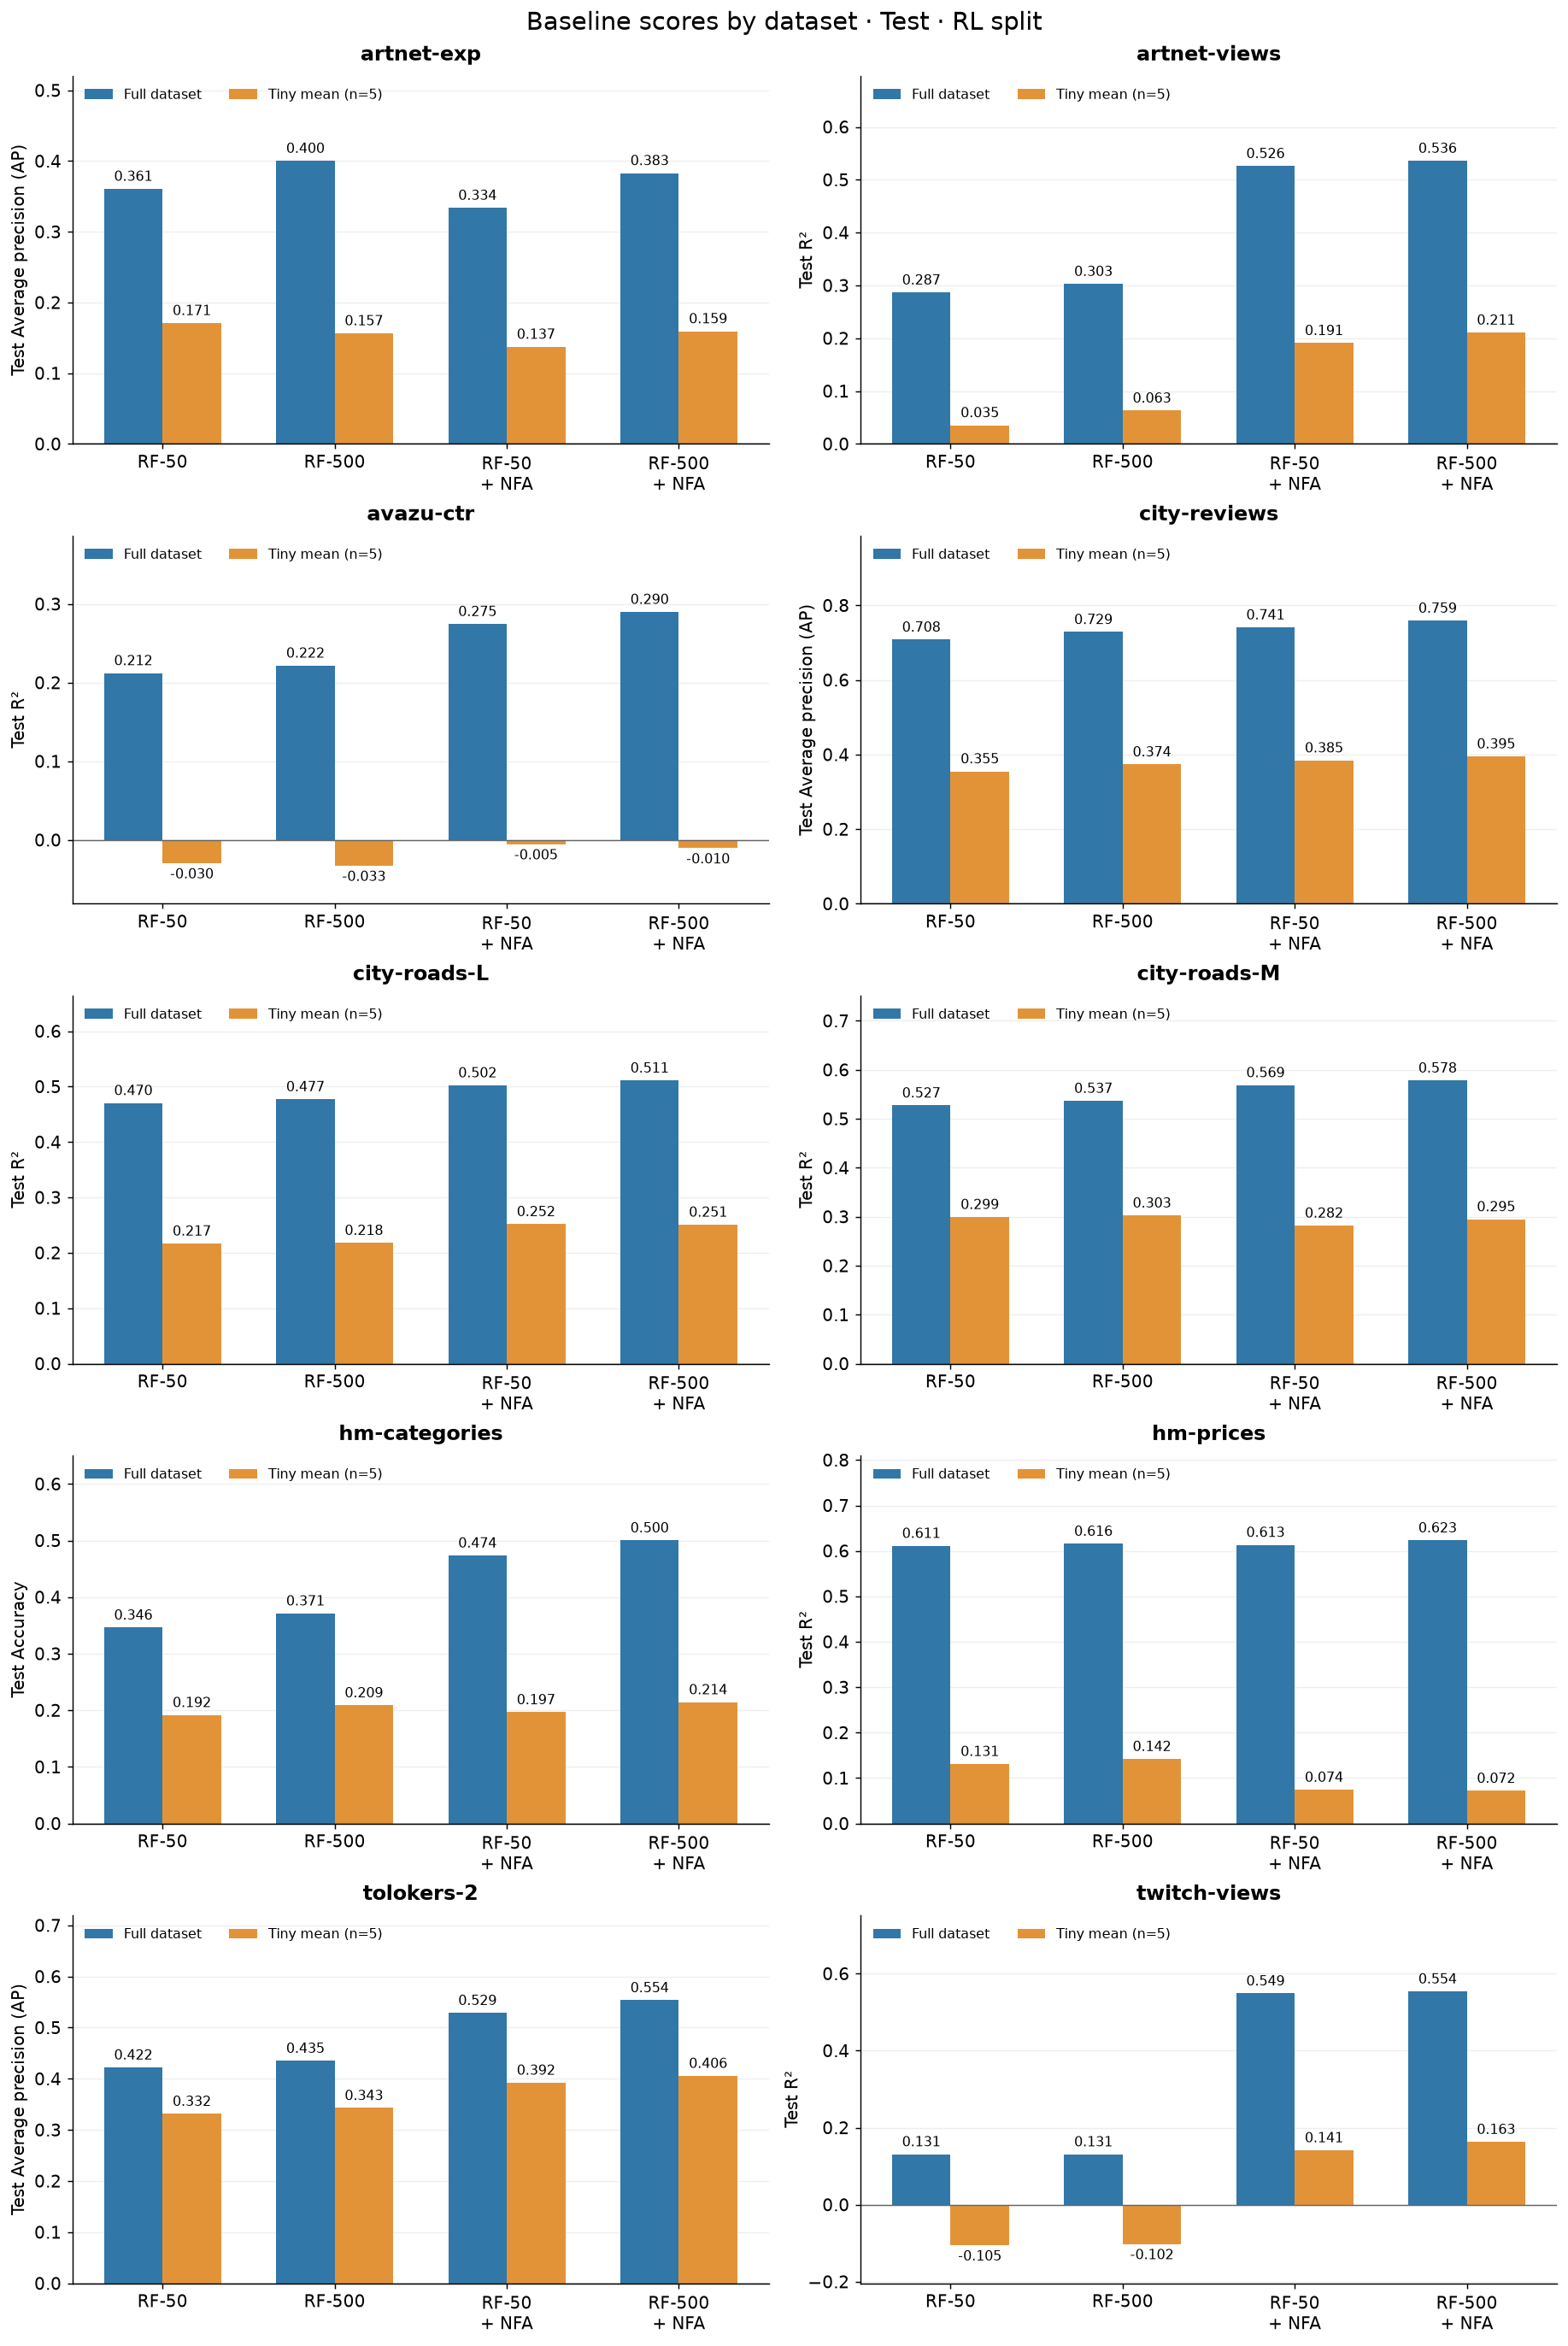

In [10]:
base_datasets = sorted(dataset_scores["base_dataset"].unique())
ncols = min(2, len(base_datasets))
nrows = (len(base_datasets) + ncols - 1) // ncols
per_dataset_fig, axes = plt.subplots(
    nrows, ncols, figsize=(7 * ncols, 4.2 * nrows),
    squeeze=False, layout="constrained",
)
method_positions = np.arange(len(method_order))
method_labels = [METHOD_LABELS.get(model, model).replace(" + ", "\n+ ") for model in method_order]
metric_labels = {"AP": "Average precision (AP)", "accuracy": "Accuracy", "R2": "R²"}
bar_width = 0.34

for ax, base_dataset in zip(axes.flat, base_datasets):
    scores = per_dataset_means.loc[base_dataset].reindex(method_order)
    counts = per_dataset_counts.loc[base_dataset].reindex(method_order)
    n_tiny = int(counts["tiny"].iloc[0])

    for offset, variant in zip((-bar_width / 2, bar_width / 2), VARIANTS):
        label = "Full dataset" if variant == "full" else f"Tiny mean (n={n_tiny})"
        bars = ax.bar(
            method_positions + offset, scores[variant], bar_width,
            color=colors[variant], label=label,
        )
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

    metric = metric_by_dataset.loc[base_dataset]
    ax.set_title(base_dataset, fontweight="bold", pad=10)
    ax.set_ylabel(f"{split_label} {metric_labels.get(metric, metric)}")
    ax.set_xticks(method_positions, method_labels)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.axhline(0, color="#666666", linewidth=0.8)
    ax.legend(frameon=False, fontsize=9, loc="upper left", ncols=2)

    values = scores.to_numpy()
    low = min(0.0, float(values.min()))
    high = max(0.0, float(values.max()))
    score_range = max(high - low, 0.1)
    ax.set_ylim(low - 0.15 * score_range if low < 0 else 0, high + 0.30 * score_range)

for ax in list(axes.flat)[len(base_datasets):]:
    ax.set_visible(False)

per_dataset_fig.suptitle(
    f"Baseline scores by dataset · {split_label} · {DATA_SPLIT} split",
    fontsize=16,
)
plt.show()

# Optional export:
# per_dataset_fig.savefig(REPO_ROOT / "baselines" / "per_dataset_scores.png", dpi=200)
